# Week 5 - Wed Lab (09/30/26) 

This code accompanies activities for the 09/30/26 lab.

**Table of Contents**

1. [Plicker Questions Code](#sec1)
2. [Cosine Similarity Whiteboard Activity - Your Task](#sec2)
3. [Wikipedia country-specific data](#sec3)
4. [Task 3](#sec4)

<a id="sec1"></a>
## 1. Plicker Questions Code

This code relates to the Question 13 on the Plicker set of questions for today. We will run the code line by line to see what is going on.

In [1]:
from datetime import datetime, timedelta

**Create a new datetime object**

In [2]:
date1 = datetime(2023, 5, 1)
type(date1)

datetime.datetime

**Create a new timedelta object**

In [3]:
delta = timedelta(days=10)
type(delta)

datetime.timedelta

In [4]:
print(delta)

10 days, 0:00:00


**Adding the two objects**

In [5]:
date2 = date1 + delta
print(date2)

2023-05-11 00:00:00


**Why is this possible?**

Let's show all methods / properties of the object:

In [6]:
dir(date1)

['__add__',
 '__class__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__ne__',
 '__new__',
 '__radd__',
 '__reduce__',
 '__reduce_ex__',
 '__replace__',
 '__repr__',
 '__rsub__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__sub__',
 '__subclasshook__',
 'astimezone',
 'combine',
 'ctime',
 'date',
 'day',
 'dst',
 'fold',
 'fromisocalendar',
 'fromisoformat',
 'fromordinal',
 'fromtimestamp',
 'hour',
 'isocalendar',
 'isoformat',
 'isoweekday',
 'max',
 'microsecond',
 'min',
 'minute',
 'month',
 'now',
 'replace',
 'resolution',
 'second',
 'strftime',
 'strptime',
 'time',
 'timestamp',
 'timetuple',
 'timetz',
 'today',
 'toordinal',
 'tzinfo',
 'tzname',
 'utcfromtimestamp',
 'utcnow',
 'utcoffset',
 'utctimetuple',
 'weekday',
 'year']

Let's look up the docstring of the method `__add__`, which is what is called when we use the + operator:

In [7]:
help(date1.__add__)

Help on method-wrapper:

__add__(value, /) unbound datetime.datetime method
    Return self+value.



**Conclusion:** There is a class method that will accept any value type and then act accordingly to figure out how to add that value to the date, if possible.

<a id="sec2"></a>
## 2. Cosine Similarity Whiteboard Activity

This activity was completed by hand, here is how to do it via Python code.

### Inputs for the problem

In [16]:
documents = [
    "Max likes Sam.",    # D1
    "Sam likes Max.",    # D2
    "Max and Sam.",      # D3
    "Winter likes fall." # D4
]

query = "Sam likes winter"

### Step 1: Create vocabulary of all terms

First I will concatenate all strings into one.

In [17]:
allText = " ".join(documents + [query])
print(allText)

Max likes Sam. Sam likes Max. Max and Sam. Winter likes fall. Sam likes winter


I don't want to have punctuation. There are several ways to do that. Let's see some:

#### Method 1: Iterate over the string, leave out punctuations

In [18]:
import string
print(string.punctuation)


!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [19]:
allText_noPunct = "".join([ch for ch in allText if not ch in string.punctuation])
print(allText_noPunct)

Max likes Sam Sam likes Max Max and Sam Winter likes fall Sam likes winter


### Method 2: Use built-in methods

Pythyn's built-in `str` class has many useful methods for translating a set of characters to another one. Let's see the method in action:

In [12]:
allText.translate(str.maketrans("", "", string.punctuation))

'Max likes Sam Sam likes Max Max and Sam Winter likes fall Sam likes winter'

What's going on?

In [13]:
print(str.maketrans("", "", string.punctuation))

{33: None, 34: None, 35: None, 36: None, 37: None, 38: None, 39: None, 40: None, 41: None, 42: None, 43: None, 44: None, 45: None, 46: None, 47: None, 58: None, 59: None, 60: None, 61: None, 62: None, 63: None, 64: None, 91: None, 92: None, 93: None, 94: None, 95: None, 96: None, 123: None, 124: None, 125: None, 126: None}


We can see that all ASCII Characters from 0-32 and from 65 to 90 are missing, because those characters will be deleted.

Here is what is happening:

```
str.maketrans(from_str, to_str, delete_chars)
#              ^          ^        ^
#           1st arg    2nd arg  3rd arg
```

* 1st argument (""): The characters you want to replace. (Empty string = replace nothing)

* 2nd argument (""): The characters to replace them with. (Empty string = no replacement mapping)

* 3rd argument (string.punctuation): The characters you want to delete entirely.

### Our vocabulary

Here is a Python one-liner that takes our variable `allText_noPunct` and find the unique words in it.

In [14]:
words = set(allText_noPunct.lower().split())
words

{'and', 'fall', 'likes', 'max', 'sam', 'winter'}

In [15]:
voc = sorted(words)
voc

['and', 'fall', 'likes', 'max', 'sam', 'winter']

### YOUR TURN

Write code to implement the other steps of the process shown in Slide 7.

**Show your process before writing any functions.**

**Use markdown to label the three remaining steps.**

### Step 2: Represent each document and the query in the vector space created by these terms

In [45]:
import pandas as pd

In [50]:
# create vectors for each document and the query

df = pd.DataFrame([
    [1, 1, 1, 0, 0, 0],  #d1
    [1, 1, 1, 0, 0, 0],  #d2
    [1, 0, 1, 1, 0, 0],  #d3
    [0, 1, 0, 0, 1, 1],  #d4
    [0, 1, 1, 0, 1, 0]   #query
],
columns=["max", "likes", "sam", "and", "winter", "fall"],
index=["d1", "d2", "d3", "d4", "query"])

print(df)

       max  likes  sam  and  winter  fall
d1       1      1    1    0       0     0
d2       1      1    1    0       0     0
d3       1      0    1    1       0     0
d4       0      1    0    0       1     1
query    0      1    1    0       1     0


### Step 3: Calculate the cosine similarity between the query and each document

Write the function for cosine similarity:

In [54]:
import numpy as np 
from numpy.linalg import norm

def cosineSimilarity(vec1, vec2):
    '''Calculate the cosine similarity between two vectors.'''
    V1 = np.array(vec1)
    V2 = np.array(vec2)
    cosine = np.dot(V1, V2) / (norm(V1) * norm(V2))
    return cosine

Get the query vector from the document vector space:

In [55]:
query_vector = df.loc["query"].values

Do the same for each document:

In [56]:
d1 = df.loc["d1"].values
d2 = df.loc["d2"].values
d3 = df.loc["d3"].values
d4 = df.loc["d4"].values

Apply function and print results:

In [60]:
print("doc1: ", cosineSimilarity(d1, query_vector))
print("doc2: ", cosineSimilarity(d2, query_vector))
print("doc3: ", cosineSimilarity(d3, query_vector))
print("doc4: ", cosineSimilarity(d4, query_vector))

doc1:  0.6666666666666667
doc2:  0.6666666666666667
doc3:  0.33333333333333337
doc4:  0.6666666666666667


### Step 4: Rank the results based on the cosine similarity

First, store the scores in a list called results:

In [61]:
results = []

for doc in ["d1", "d2", "d3", "d4"]:
    doc_vector = df.loc[doc].values
    score = cosineSimilarity(doc_vector, query_vector)
    results.append((doc, score))

Then sort result to rank the scores:


In [62]:
results.sort(key=lambda x: x[1], reverse=True)

print(results)

[('d1', np.float64(0.6666666666666667)), ('d2', np.float64(0.6666666666666667)), ('d4', np.float64(0.6666666666666667)), ('d3', np.float64(0.33333333333333337))]


In [66]:
for doc, score in results:
    print(f"{doc}: {round(score, 3)}") #print neatly

d1: 0.667
d2: 0.667
d4: 0.667
d3: 0.333


<a id="sec3"></a>
## 3. Wikipedia Country-Specific Data

If we know the URL of a date, for example:

```
https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv
```

we can use pandas to read the content of the file into a dataframe. 

In [67]:
import pandas as pd

url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

df = pd.read_csv(url, sep='\t')

df.head()

HTTPError: HTTP Error 403: Forbidden

Why did this happen? Wikimedia didn't like that we didn't identify ourselves. This is why we need to first get data with requests, then read it from pandas.

In [129]:
import pandas as pd
import requests, io

url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

headers = {'User-Agent': 'MyDataAnalysisScript/1.0 (contact: wendywellesley@gmail.com)'}
response = requests.get(url, headers=headers)

df = pd.read_csv(io.StringIO(response.text), sep='\t')
df.head()

,Algeria,DZ,ar.wikipedia,3947,Ø°ÙØ§Ø¡_Ø§ØµØ·ÙØ§Ø¹Ù,Q11660,122
0,Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
1,Argentina,AR,es.wikipedia,327209,JosÃ©_Mourinho,Q79983,114
2,Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
3,Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119
4,Argentina,AR,es.wikipedia,5640452,Michael_Jackson,Q2831,177


The dataframe doesn't have column name. 

**Your task:** Read the README file to find out the column names and add them to the dataframe.


In [130]:
df = pd.read_csv(io.StringIO(response.text), sep='\t', header=None) #need none so that first row doesn't get turned into header

df.columns = ["country", "country_code", "project", "page_id", "page_title", "item_id", "gbc"]

df.head()

,country,country_code,project,page_id,page_title,item_id,gbc
0,Algeria,DZ,ar.wikipedia,3947,Ø°ÙØ§Ø¡_Ø§ØµØ·ÙØ§Ø¹Ù,Q11660,122
1,Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
2,Argentina,AR,es.wikipedia,327209,JosÃ©_Mourinho,Q79983,114
3,Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
4,Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119


<a id="sec4"></a>

## Task 3
**Question:**  How popular were the top most recent Kdramas around the world in the month of September 2026?

#### Find the ten highest rated most popular Kdramas from 2026:
1. Teach You a Lesson (9.0) | Wikipedia: Teach You a Lesson
2. Four Hands, Two Sonatas (8.7) | Wikipedia: Four Hands, Two Sonatas
3. Bloodhounds Season 2 (8.7) | Wikipedia: Bloodhounds (TV series)
4. Agent Kim Reactivated (8.6) | Wikipedia: Agent Kim Reactivated
5. Yumi's Cells Season 3 (8.6) | Wikipedia: Yumi's Cells
6. We Are All Trying Here (8.5) | Wikipedia: We Are All Trying Here
7. A Shop for Killers Season 2 (8.5) | Wikipedia: A Shop for Killers
8. The WONDERfools (8.5) | Wikipedia: The Wonderfools
9. The Legend of Kitchen Soldier (8.5) | Wikipedia: The Legend of Kitchen Soldier
10. A Bona Fide Killer (8.4) | Wikipedia: A Bona Fide Killer

Store the ten kdramas and their ratings into lists:

In [214]:
kdramas = [
    "Teach You a Lesson",
    "Four_Hands,_Two_Sonatas",
    "Bloodhounds Season 2",
    "Agent Kim Reactivated",
    "Yumi's Cells Season 3",
    "We Are All Trying Here",
    "A Shop for Killers Season 2",
    "The WONDERfools",
    "The Legend of Kitchen Soldier",
    "A Bona Fide Killer"
]

kdramas_wiki = [
    "Teach_You_a_Lesson",
    "Four_Hands,_Two_Sonatas",
    "Bloodhounds_(TV_series)",
    "Agent_Kim_Reactivated",
    "Yumi's_Cells", # not appearing
    "We_Are_All_Trying_Here",
    "A_Shop_for_Killers",
    "The_Wonderfools",
    "The_Legend_of_Kitchen_Soldier",
    "A_Bona_Fide_Killer"
]

# enter ratings in same order
ratings = [
    9.0,
    8.7,
    8.7,
    8.6,
    8.6,
    8.5,
    8.5,
    8.5,
    8.5,
    8.4
]


top_rated_2026_kdramas = pd.DataFrame({
    "page_title": kdramas,
    "wiki_title": kdramas_wiki,
    "mdl_rating": ratings
})

top_rated_2026_kdramas

,page_title,wiki_title,mdl_rating
0,Teach You a Lesson,Teach_You_a_Lesson,9.0
1,"Four_Hands,_Two_Sonatas","Four_Hands,_Two_Sonatas",8.7
2,Bloodhounds Season 2,Bloodhounds_(TV_series),8.7
3,Agent Kim Reactivated,Agent_Kim_Reactivated,8.6
4,Yumi's Cells Season 3,Yumi's_Cells,8.6
5,We Are All Trying Here,We_Are_All_Trying_Here,8.5
6,A Shop for Killers Season 2,A_Shop_for_Killers,8.5
7,The WONDERfools,The_Wonderfools,8.5
8,The Legend of Kitchen Soldier,The_Legend_of_Kitchen_Soldier,8.5
9,A Bona Fide Killer,A_Bona_Fide_Killer,8.4


Now, we can write a script to retreive data from Wikimedia to get the daily page views for the entire month of September 2026:

First import datetime library:

In [215]:
from datetime import date, timedelta

In [216]:
base_url = "https://analytics.wikimedia.org/published/datasets/country_project_page/"

headers = {'User-Agent': 'MyDataAnalysisScript/1.0 (contact: wendywellesley@gmail.com)'}

kdrama_titles = set(kdramas_wiki)
results = []

#set dates for month of sept in 2026
start_date = date(2026, 9, 1) 
end_date = date(2026, 10, 1)

In [233]:
while start_date < end_date:
    date_string = start_date.isoformat()
    url = f"{base_url}{date_string}.tsv"
    
    response = requests.get(url, headers=headers)

    results_df = pd.read_csv(io.StringIO(response.text), sep="\t", header=None)
    results_df.columns = ["country", "country_code", "project", "page_id", "page_title", "item_id", "gbc"]

    # keep only English wiki pages of the ten kdramas
    results_df = results_df[
        (results_df["project"] == "en.wikipedia") &
        (results_df["page_title"].isin(kdrama_titles))
    ].copy()

    # each file is daily pageviews 
    results_df["date"] = date_string

    results.append(results_df)

    start_date += timedelta(days=1) #increment to next day

In [234]:
# combine the filtered records from days in sept
sept_kdrama_views = pd.concat(
    results,
    ignore_index=True
)

sept_kdrama_views.head()

,country,country_code,project,page_id,page_title,item_id,gbc,date
0,Malaysia,MY,en.wikipedia,75697706,A_Shop_for_Killers,Q123999260,160,2026-09-01
1,Singapore,SG,en.wikipedia,79560156,Teach_You_a_Lesson,Q137844128,129,2026-09-01
2,United States,US,en.wikipedia,79560156,Teach_You_a_Lesson,Q137844128,577,2026-09-01
3,India,IN,en.wikipedia,82034667,"Four_Hands,_Two_Sonatas",Q137271520,1082,2026-09-01
4,Australia,AU,en.wikipedia,79560156,Teach_You_a_Lesson,Q137844128,106,2026-09-01


In [235]:
print("Rows:", len(sept_kdrama_views))
print("Dates:", sept_kdrama_views["date"].nunique())
print("Shows found:", sept_kdrama_views["page_title"].nunique())

Rows: 1260
Dates: 30
Shows found: 9


In [236]:
found_titles = set(sept_kdrama_views["page_title"])
missing_titles = kdrama_titles - found_titles

print("Found titles:")
print(sorted(found_titles))

print("Missing titles:")
print(sorted(missing_titles))

Found titles:
['A_Bona_Fide_Killer', 'A_Shop_for_Killers', 'Agent_Kim_Reactivated', 'Bloodhounds_(TV_series)', 'Four_Hands,_Two_Sonatas', 'Teach_You_a_Lesson', 'The_Legend_of_Kitchen_Soldier', 'The_Wonderfools', 'We_Are_All_Trying_Here']
Missing titles:
["Yumi's_Cells"]


It appears that we were able to find data for all but one Kdrama, Yumi's Cells.

In [237]:
# double check if Yumi's Cells even exists in data
df[
    df["page_title"].str.contains(
        "Yumi", case=False, na=False #check Yumi in case apostrophe messing up things
    )
][["page_title", "project"]]

,page_title,project
43456,Hi_Hi_Puffy_AmiYumi,en.wikipedia
86836,Yumi_Nu,en.wikipedia
145125,Ayumi_Hamasaki,en.wikipedia


For some reason, it appaers that *Yumi's Cells* seems to not be included in the data, despite having a Wikipedia page that was created earlier too. However when getting pageviews with mwviews, it appears to be included. Thus, I decided to get that data separately and add it in.

In [238]:
yumi_data = p.article_views(
    "en.wikipedia",
    ["Yumi's_Cells"],
    start="20260901",
    end="20260930"
)

print(yumi_data)

defaultdict(<class 'dict'>, {datetime.datetime(2026, 9, 1, 0, 0): {"Yumi's_Cells": 427}, datetime.datetime(2026, 9, 2, 0, 0): {"Yumi's_Cells": 382}, datetime.datetime(2026, 9, 3, 0, 0): {"Yumi's_Cells": 387}, datetime.datetime(2026, 9, 4, 0, 0): {"Yumi's_Cells": 359}, datetime.datetime(2026, 9, 5, 0, 0): {"Yumi's_Cells": 411}, datetime.datetime(2026, 9, 6, 0, 0): {"Yumi's_Cells": 500}, datetime.datetime(2026, 9, 7, 0, 0): {"Yumi's_Cells": 434}, datetime.datetime(2026, 9, 8, 0, 0): {"Yumi's_Cells": 378}, datetime.datetime(2026, 9, 9, 0, 0): {"Yumi's_Cells": 384}, datetime.datetime(2026, 9, 10, 0, 0): {"Yumi's_Cells": 385}, datetime.datetime(2026, 9, 11, 0, 0): {"Yumi's_Cells": 385}, datetime.datetime(2026, 9, 12, 0, 0): {"Yumi's_Cells": 352}, datetime.datetime(2026, 9, 13, 0, 0): {"Yumi's_Cells": 424}, datetime.datetime(2026, 9, 14, 0, 0): {"Yumi's_Cells": 355}, datetime.datetime(2026, 9, 15, 0, 0): {"Yumi's_Cells": 393}, datetime.datetime(2026, 9, 16, 0, 0): {"Yumi's_Cells": 382}, date

In [239]:
yumi_df = pd.DataFrame(yumi_data)
yumi_df.index.name = "date"

yumi_df.head()

,2026-09-01,2026-09-02,2026-09-03,2026-09-04,2026-09-05,2026-09-06,2026-09-07,2026-09-08,2026-09-09,2026-09-10,...,2026-09-21,2026-09-22,2026-09-23,2026-09-24,2026-09-25,2026-09-26,2026-09-27,2026-09-28,2026-09-29,2026-09-30
date,,,,,,,,,,,,,,,,,,,,,
Yumi's_Cells,427,382,387,359,411,500,434,378,384,385,...,322,334,363,363,305,332,355,351,406,343


This df is in wide format right now; we need to change it to match the format of sept_kdrama_views as long df:

In [240]:
yumi_df.index.name = "page_title"

#convert dates from cols into rows
yumi_long = (
    yumi_df
    .reset_index()
    .melt(
        id_vars="page_title",
        var_name="date",
        value_name="gbc"
    )
)
yumi_long["date"] = pd.to_datetime(yumi_long["date"]).dt.strftime("%Y-%m-%d") #convert to date format using regex

display(yumi_long.head())

,page_title,date,gbc
0,Yumi's_Cells,2026-09-01,427
1,Yumi's_Cells,2026-09-02,382
2,Yumi's_Cells,2026-09-03,387
3,Yumi's_Cells,2026-09-04,359
4,Yumi's_Cells,2026-09-05,411


Append to the sept_kdrama_views df:

In [241]:
sept_kdrama_views = pd.concat(
    [sept_kdrama_views, yumi_long],
    ignore_index=True
)

sept_kdrama_views

,country,country_code,project,page_id,page_title,item_id,gbc,date
0,Malaysia,MY,en.wikipedia,75697706.0,A_Shop_for_Killers,Q123999260,160,2026-09-01
1,Singapore,SG,en.wikipedia,79560156.0,Teach_You_a_Lesson,Q137844128,129,2026-09-01
2,United States,US,en.wikipedia,79560156.0,Teach_You_a_Lesson,Q137844128,577,2026-09-01
3,India,IN,en.wikipedia,82034667.0,"Four_Hands,_Two_Sonatas",Q137271520,1082,2026-09-01
4,Australia,AU,en.wikipedia,79560156.0,Teach_You_a_Lesson,Q137844128,106,2026-09-01
...,...,...,...,...,...,...,...,...
1285,NaN,NaN,NaN,NaN,Yumi's_Cells,NaN,332,2026-09-26
1286,NaN,NaN,NaN,NaN,Yumi's_Cells,NaN,355,2026-09-27
1287,NaN,NaN,NaN,NaN,Yumi's_Cells,NaN,351,2026-09-28
1288,NaN,NaN,NaN,NaN,Yumi's_Cells,NaN,406,2026-09-29


Now I have the pageviews (gbc) for Yumi's Cells, but I don't have the country for them, which means the bar chart for ranking pageviews by country will be missing Yumi's Cells data.

In [242]:
#save to csv file
sept_kdrama_views.to_csv(
    "sept_kdrama_2026_views.csv",
    index=False
)

#### Total views for each show (over all countries)

In [243]:
import matplotlib.pyplot as plt

In [244]:
show_totals = (
    sept_kdrama_views
    .groupby("page_title")["gbc"]
    .sum()
    .sort_values(ascending=False)
)

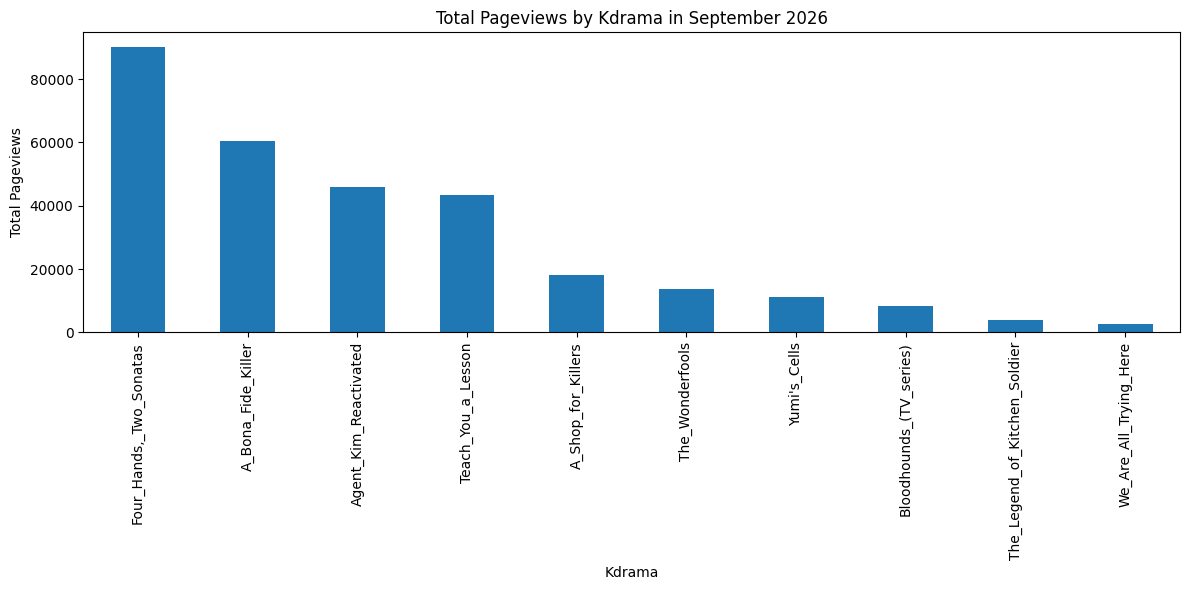

In [245]:
show_totals.plot(kind="bar", figsize=(12, 6))

plt.title("Total Pageviews by Kdrama in September 2026")
plt.xlabel("Kdrama")
plt.ylabel("Total Pageviews")
plt.tight_layout()
plt.show()

#### Total views by country over all Kdramas

In [246]:
country_totals = (
    sept_kdrama_views
    .groupby("country")["gbc"]
    .sum()
    .sort_values(ascending=False)
)

Number of countries: 18


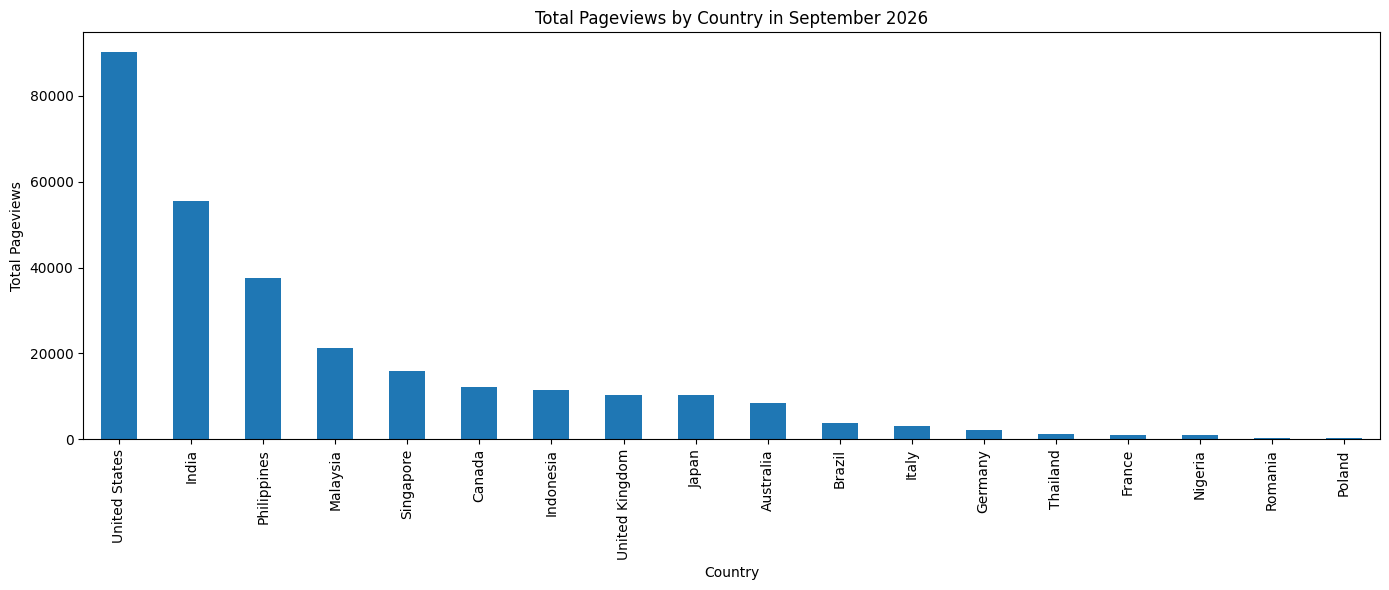

In [247]:
print("Number of countries:", (country_totals > 0).sum()) #ensure only countries with positive views are counted

country_totals.plot(kind="bar", figsize=(14, 6))

plt.title("Total Pageviews by Country in September 2026")
plt.xlabel("Country")
plt.ylabel("Total Pageviews")
plt.tight_layout()
plt.show()

#### Does the popularity in Wikipedia pageviews correlate to the rating for the shows in MyDramaList?

View the order of the dramas by their rating again:

In [248]:
top_rated_2026_kdramas

,page_title,wiki_title,mdl_rating
0,Teach You a Lesson,Teach_You_a_Lesson,9.0
1,"Four_Hands,_Two_Sonatas","Four_Hands,_Two_Sonatas",8.7
2,Bloodhounds Season 2,Bloodhounds_(TV_series),8.7
3,Agent Kim Reactivated,Agent_Kim_Reactivated,8.6
4,Yumi's Cells Season 3,Yumi's_Cells,8.6
5,We Are All Trying Here,We_Are_All_Trying_Here,8.5
6,A Shop for Killers Season 2,A_Shop_for_Killers,8.5
7,The WONDERfools,The_Wonderfools,8.5
8,The Legend of Kitchen Soldier,The_Legend_of_Kitchen_Soldier,8.5
9,A Bona Fide Killer,A_Bona_Fide_Killer,8.4


I think the Wikipedia pageviews somewhoat correlate to the ratings for the shows in MyDramaList, as Four Hands, Two Sonatas is the top most-visited page and has the second highest rating (8.7). However, A Bona Fide Killer has the lowest rating of the ten (8.4), yet is the second most-visited page, so there are also other factors that are playing into pageviews besides rating.